# CIFAR-10 Single-Head ViT: End-to-End Softmax / LayerNorm Curve Analysis

This notebook trains a small **single-head, 3-block ViT** on CIFAR-10 using manually written:

- Q/K/V linear projections
- single-head self-attention
- Softmax
- LayerNorm
- MLP and residual connections

No `nn.MultiheadAttention`, `nn.TransformerEncoder`, or `nn.LayerNorm` is used.

After training, the notebook collects **token-wise end-to-end input/output curves**:

- **Softmax:** one query token gives one `attention score -> probability` curve.
- **LayerNorm:** one token gives one `input activation -> normalized output` empirical response curve.

The purpose is to directly inspect whether these operator curves remain stable enough across tokens to justify later PWLF / multi-threshold approximation.


In [1]:
# ============================================================
# Imports and configuration
# ============================================================

import math
import random
from collections import defaultdict
from pathlib import Path

import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

# ----------------------------
# General configuration
# ----------------------------

DATA_ROOT = "./data"
OUT_DIR = "./runs/cifar10_singlehead_vit"

EPOCHS = 400
BATCH_SIZE = 256
NUM_WORKERS = 4

# LR = 3e-4
LR = 1e-3
WEIGHT_DECAY = 0.05
SEED = 42

# Model configuration
IMAGE_SIZE = 32
PATCH_SIZE = 4
DIM = 128
DEPTH = 3
MLP_RATIO = 4.0
DROPOUT = 0.1
ATTN_DROPOUT = 0.0

# Curve collection configuration
CURVE_MAX_BATCHES = 20
MAX_TOKENS_PER_MODULE = 300

# Set this to True if you want to train from scratch in this notebook.
TRAIN_MODEL = False

# If TRAIN_MODEL=False, this checkpoint will be loaded.
# If None, OUT_DIR / "best.pt" is used.
CKPT_PATH = None


In [2]:
# ============================================================
# Reproducibility
# ============================================================

def seed_everything(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

seed_everything(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)


Device: cuda


## 1. Curve collector

The collector intentionally ignores internal Softmax / LayerNorm parameters.

It only stores the **actual input-output relationship seen by each token**.


In [3]:
# ============================================================
# Token-wise end-to-end curve collector
# ============================================================

class CurveCollector:
    """
    Collect only end-to-end operator curves.

    LayerNorm:
        one token:
            x[D] -> LayerNorm(x)[D]

    Softmax:
        one query token:
            score[N] -> softmax(score)[N]

    One token therefore produces one curve.
    """

    def __init__(self, max_tokens_per_module=300):
        self.max_tokens_per_module = max_tokens_per_module

        self.layernorm_curves = defaultdict(list)
        self.softmax_curves = defaultdict(list)

    @torch.no_grad()
    def add_layernorm(self, name, x, y, mean=None, std=None):
        # x, y: [B, N, D]
        x = x.detach().float().cpu()
        y = y.detach().float().cpu()

        # [B, N, D] -> [B*N, D]
        x = x.reshape(-1, x.shape[-1])
        y = y.reshape(-1, y.shape[-1])

        remaining = (
            self.max_tokens_per_module
            - len(self.layernorm_curves[name])
        )

        if remaining <= 0:
            return

        n = min(remaining, x.shape[0])
        indices = torch.randperm(x.shape[0])[:n]

        for idx in indices:
            self.layernorm_curves[name].append(
                (
                    x[idx].numpy(),
                    y[idx].numpy(),
                )
            )

    @torch.no_grad()
    def add_softmax(self, name, scores, probs):
        # scores, probs: [B, N, N]
        scores = scores.detach().float().cpu()
        probs = probs.detach().float().cpu()

        # [B, N, N] -> [B*N, N]
        scores = scores.reshape(-1, scores.shape[-1])
        probs = probs.reshape(-1, probs.shape[-1])

        remaining = (
            self.max_tokens_per_module
            - len(self.softmax_curves[name])
        )

        if remaining <= 0:
            return

        n = min(remaining, scores.shape[0])
        indices = torch.randperm(scores.shape[0])[:n]

        for idx in indices:
            self.softmax_curves[name].append(
                (
                    scores[idx].numpy(),
                    probs[idx].numpy(),
                )
            )


## 2. Manual LayerNorm

In [4]:
# ============================================================
# Manual LayerNorm
# ============================================================

class ManualLayerNorm(nn.Module):
    """
    Explicit LayerNorm:
        y = gamma * (x - mean) / sqrt(var + eps) + beta

    nn.LayerNorm is NOT used.
    """

    def __init__(self, dim, eps=1e-5, name="ln"):
        super().__init__()

        self.gamma = nn.Parameter(torch.ones(dim))
        self.beta = nn.Parameter(torch.zeros(dim))

        self.eps = eps
        self.name = name
        self.collector = None

    def set_collector(self, collector):
        self.collector = collector

    def forward(self, x):
        mean = x.mean(dim=-1, keepdim=True)
        var = ((x - mean) ** 2).mean(dim=-1, keepdim=True)
        std = torch.sqrt(var + self.eps)

        y = (x - mean) / std
        y = y * self.gamma + self.beta

        if self.collector is not None and not self.training:
            self.collector.add_layernorm(
                self.name,
                x,
                y,
                mean,
                std,
            )

        return y


## 3. Manual single-head self-attention

In [5]:
# ============================================================
# Manual single-head self-attention
# ============================================================

class SingleHeadSelfAttention(nn.Module):
    """
    Explicit single-head self-attention:

        Q = X Wq
        K = X Wk
        V = X Wv

        scores = Q K^T / sqrt(d)
        probs  = softmax(scores)

        output = probs V
        output = Wo(output)

    nn.MultiheadAttention is NOT used.
    """

    def __init__(
        self,
        dim,
        attn_dropout=0.0,
        proj_dropout=0.0,
        name="attn",
    ):
        super().__init__()

        self.dim = dim
        self.scale = dim ** -0.5

        self.name = name
        self.collector = None

        self.q_proj = nn.Linear(dim, dim)
        self.k_proj = nn.Linear(dim, dim)
        self.v_proj = nn.Linear(dim, dim)

        self.out_proj = nn.Linear(dim, dim)

        self.attn_dropout = nn.Dropout(attn_dropout)
        self.proj_dropout = nn.Dropout(proj_dropout)

    def set_collector(self, collector):
        self.collector = collector

    def forward(self, x):
        q = self.q_proj(x)
        k = self.k_proj(x)
        v = self.v_proj(x)

        scores = torch.matmul(
            q,
            k.transpose(-2, -1),
        ) * self.scale

        # Explicit Softmax.
        # Writing it manually here makes later replacement easier.
        score_max = scores.max(
            dim=-1,
            keepdim=True,
        ).values

        exp_scores = torch.exp(
            scores - score_max
        )

        probs = exp_scores / exp_scores.sum(
            dim=-1,
            keepdim=True,
        )

        if self.collector is not None and not self.training:
            self.collector.add_softmax(
                self.name,
                scores,
                probs,
            )

        probs = self.attn_dropout(probs)

        out = torch.matmul(probs, v)
        out = self.out_proj(out)
        out = self.proj_dropout(out)

        return out


## 4. MLP and Transformer block

In [6]:
# ============================================================
# MLP
# ============================================================

class MLP(nn.Module):

    def __init__(
        self,
        dim,
        hidden_dim,
        dropout=0.0,
    ):
        super().__init__()

        self.fc1 = nn.Linear(dim, hidden_dim)
        self.act = nn.GELU()
        self.fc2 = nn.Linear(hidden_dim, dim)

        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        x = self.fc1(x)
        x = self.act(x)
        x = self.dropout(x)

        x = self.fc2(x)
        x = self.dropout(x)

        return x


# ============================================================
# Transformer block
# ============================================================

class TransformerBlock(nn.Module):
    """
    Pre-LN encoder block:

        x = x + Attention(LN1(x))
        x = x + MLP(LN2(x))
    """

    def __init__(
        self,
        dim,
        mlp_ratio=4.0,
        dropout=0.0,
        attn_dropout=0.0,
        block_id=0,
    ):
        super().__init__()

        self.ln1 = ManualLayerNorm(
            dim,
            name=f"block{block_id}.ln1",
        )

        self.attn = SingleHeadSelfAttention(
            dim,
            attn_dropout=attn_dropout,
            proj_dropout=dropout,
            name=f"block{block_id}.softmax",
        )

        self.ln2 = ManualLayerNorm(
            dim,
            name=f"block{block_id}.ln2",
        )

        self.mlp = MLP(
            dim=dim,
            hidden_dim=int(dim * mlp_ratio),
            dropout=dropout,
        )

    def set_collector(self, collector):
        self.ln1.set_collector(collector)
        self.attn.set_collector(collector)
        self.ln2.set_collector(collector)

    def forward(self, x):
        x = x + self.attn(
            self.ln1(x)
        )

        x = x + self.mlp(
            self.ln2(x)
        )

        return x


## 5. CIFAR-10 ViT

In [7]:
# ============================================================
# CIFAR-10 single-head ViT
# ============================================================

class CIFAR10SingleHeadViT(nn.Module):

    def __init__(
        self,
        image_size=32,
        patch_size=4,
        in_channels=3,
        num_classes=10,
        dim=128,
        depth=3,
        mlp_ratio=4.0,
        dropout=0.1,
        attn_dropout=0.0,
    ):
        super().__init__()

        assert image_size % patch_size == 0

        self.image_size = image_size
        self.patch_size = patch_size
        self.dim = dim

        patches_per_side = (
            image_size // patch_size
        )

        self.num_patches = (
            patches_per_side ** 2
        )

        patch_dim = (
            in_channels
            * patch_size
            * patch_size
        )

        self.patch_proj = nn.Linear(
            patch_dim,
            dim,
        )

        self.cls_token = nn.Parameter(
            torch.zeros(1, 1, dim)
        )

        self.pos_embed = nn.Parameter(
            torch.zeros(
                1,
                self.num_patches + 1,
                dim,
            )
        )

        self.pos_drop = nn.Dropout(dropout)

        self.blocks = nn.ModuleList([
            TransformerBlock(
                dim=dim,
                mlp_ratio=mlp_ratio,
                dropout=dropout,
                attn_dropout=attn_dropout,
                block_id=i,
            )
            for i in range(depth)
        ])

        self.final_ln = ManualLayerNorm(
            dim,
            name="final_ln",
        )

        self.head = nn.Linear(
            dim,
            num_classes,
        )

        self._init_weights()

    def _init_weights(self):
        nn.init.trunc_normal_(
            self.pos_embed,
            std=0.02,
        )

        nn.init.trunc_normal_(
            self.cls_token,
            std=0.02,
        )

        for m in self.modules():
            if isinstance(m, nn.Linear):
                nn.init.trunc_normal_(
                    m.weight,
                    std=0.02,
                )

                if m.bias is not None:
                    nn.init.zeros_(m.bias)

    def set_collector(self, collector):
        for block in self.blocks:
            block.set_collector(
                collector
            )

        self.final_ln.set_collector(
            collector
        )

    def clear_collector(self):
        self.set_collector(None)

    def patchify(self, x):
        p = self.patch_size

        x = x.unfold(
            2,
            p,
            p,
        ).unfold(
            3,
            p,
            p,
        )

        x = x.permute(
            0,
            2,
            3,
            1,
            4,
            5,
        ).contiguous()

        x = x.view(
            x.size(0),
            self.num_patches,
            -1,
        )

        return x

    def forward(self, x):
        x = self.patchify(x)
        x = self.patch_proj(x)

        cls = self.cls_token.expand(
            x.size(0),
            -1,
            -1,
        )

        x = torch.cat(
            [cls, x],
            dim=1,
        )

        x = x + self.pos_embed
        x = self.pos_drop(x)

        for block in self.blocks:
            x = block(x)

        x = self.final_ln(x)

        cls_out = x[:, 0]
        logits = self.head(cls_out)

        return logits


def build_model():
    return CIFAR10SingleHeadViT(
        image_size=IMAGE_SIZE,
        patch_size=PATCH_SIZE,
        num_classes=10,
        dim=DIM,
        depth=DEPTH,
        mlp_ratio=MLP_RATIO,
        dropout=DROPOUT,
        attn_dropout=ATTN_DROPOUT,
    )


## 6. CIFAR-10 data loaders

In [8]:
# ============================================================
# Dataset
# ============================================================

def make_loaders(
    data_root="./data",
    batch_size=256,
    num_workers=4,
    seed=42,
):

    train_tf = transforms.Compose([
        transforms.RandomCrop(
            32,
            padding=4,
        ),
        transforms.RandomHorizontalFlip(),
        transforms.ToTensor(),
        transforms.Normalize(
            mean=(
                0.4914,
                0.4822,
                0.4465,
            ),
            std=(
                0.2470,
                0.2435,
                0.2616,
            ),
        ),
    ])

    eval_tf = transforms.Compose([
        transforms.ToTensor(),
        transforms.Normalize(
            mean=(
                0.4914,
                0.4822,
                0.4465,
            ),
            std=(
                0.2470,
                0.2435,
                0.2616,
            ),
        ),
    ])

    full_train_aug = datasets.CIFAR10(
        root=data_root,
        train=True,
        download=True,
        transform=train_tf,
    )

    full_train_eval = datasets.CIFAR10(
        root=data_root,
        train=True,
        download=False,
        transform=eval_tf,
    )

    test_set = datasets.CIFAR10(
        root=data_root,
        train=False,
        download=True,
        transform=eval_tf,
    )

    g = torch.Generator().manual_seed(seed)

    indices = torch.randperm(
        len(full_train_aug),
        generator=g,
    ).tolist()

    train_indices = indices[:45_000]
    val_indices = indices[45_000:]

    train_set = Subset(
        full_train_aug,
        train_indices,
    )

    # Same training samples, but augmentation disabled.
    train_eval_set = Subset(
        full_train_eval,
        train_indices,
    )

    val_set = Subset(
        full_train_eval,
        val_indices,
    )

    loader_kwargs = dict(
        batch_size=batch_size,
        num_workers=num_workers,
        pin_memory=True,
    )

    train_loader = DataLoader(
        train_set,
        shuffle=True,
        drop_last=True,
        **loader_kwargs,
    )

    train_eval_loader = DataLoader(
        train_eval_set,
        shuffle=False,
        drop_last=False,
        **loader_kwargs,
    )

    val_loader = DataLoader(
        val_set,
        shuffle=False,
        drop_last=False,
        **loader_kwargs,
    )

    test_loader = DataLoader(
        test_set,
        shuffle=False,
        drop_last=False,
        **loader_kwargs,
    )

    return (
        train_loader,
        train_eval_loader,
        val_loader,
        test_loader,
    )


train_loader, train_eval_loader, val_loader, test_loader = make_loaders(
    data_root=DATA_ROOT,
    batch_size=BATCH_SIZE,
    num_workers=NUM_WORKERS,
    seed=SEED,
)

print(
    len(train_loader.dataset),
    len(val_loader.dataset),
    len(test_loader.dataset),
)


45000 5000 10000


## 7. Training and evaluation

In [9]:
# ============================================================
# Evaluation
# ============================================================

@torch.no_grad()
def evaluate(
    model,
    loader,
    device,
):
    model.eval()

    criterion = nn.CrossEntropyLoss()

    total = 0
    correct = 0
    loss_sum = 0.0

    for images, labels in loader:

        images = images.to(
            device,
            non_blocking=True,
        )

        labels = labels.to(
            device,
            non_blocking=True,
        )

        logits = model(images)
        loss = criterion(
            logits,
            labels,
        )

        total += labels.size(0)

        correct += (
            logits.argmax(dim=1)
            == labels
        ).sum().item()

        loss_sum += (
            loss.item()
            * labels.size(0)
        )

    return (
        loss_sum / total,
        correct / total,
    )


# ============================================================
# Training
# ============================================================

def train_model(
    model,
    train_loader,
    val_loader,
    device,
    epochs=100,
    lr=3e-4,
    weight_decay=0.05,
    out_dir="./runs/cifar10_singlehead_vit",
):

    out_dir = Path(out_dir)
    out_dir.mkdir(
        parents=True,
        exist_ok=True,
    )

    criterion = nn.CrossEntropyLoss()

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=lr,
        weight_decay=weight_decay,
    )

    scheduler = (
        torch.optim.lr_scheduler.CosineAnnealingLR(
            optimizer,
            T_max=epochs,
        )
    )

    best_val_acc = 0.0

    for epoch in range(
        1,
        epochs + 1,
    ):

        model.train()

        total = 0
        correct = 0
        loss_sum = 0.0

        for images, labels in train_loader:

            images = images.to(
                device,
                non_blocking=True,
            )

            labels = labels.to(
                device,
                non_blocking=True,
            )

            optimizer.zero_grad(
                set_to_none=True
            )

            logits = model(images)

            loss = criterion(
                logits,
                labels,
            )

            loss.backward()
            optimizer.step()

            total += labels.size(0)

            correct += (
                logits.argmax(dim=1)
                == labels
            ).sum().item()

            loss_sum += (
                loss.item()
                * labels.size(0)
            )

        scheduler.step()

        train_loss = loss_sum / total
        train_acc = correct / total

        val_loss, val_acc = evaluate(
            model,
            val_loader,
            device,
        )

        print(
            f"Epoch {epoch:03d}/{epochs} | "
            f"lr={scheduler.get_last_lr()[0]:.3e} | "
            f"train loss={train_loss:.4f} "
            f"acc={train_acc:.4f} | "
            f"val loss={val_loss:.4f} "
            f"acc={val_acc:.4f}"
        )

        torch.save(
            {
                "epoch": epoch,
                "model": model.state_dict(),
                "optimizer": optimizer.state_dict(),
                "val_acc": val_acc,
            },
            out_dir / "last.pt",
        )

        if val_acc > best_val_acc:

            best_val_acc = val_acc

            torch.save(
                {
                    "epoch": epoch,
                    "model": model.state_dict(),
                    "val_acc": val_acc,
                },
                out_dir / "best.pt",
            )

    print(
        f"Best validation accuracy: "
        f"{best_val_acc:.4f}"
    )


def load_checkpoint(
    model,
    ckpt_path,
    device,
):

    ckpt = torch.load(
        ckpt_path,
        map_location=device,
    )

    model.load_state_dict(
        ckpt["model"]
    )

    print(
        f"Loaded checkpoint: {ckpt_path} | "
        f"epoch={ckpt.get('epoch', '?')} | "
        f"val_acc={ckpt.get('val_acc', '?')}"
    )


## 8. Build / train / load model

In [10]:
# ============================================================
# Build model
# ============================================================

model = build_model().to(device)

num_params = sum(
    p.numel()
    for p in model.parameters()
)

print(model)
print(f"Parameters: {num_params:,}")


CIFAR10SingleHeadViT(
  (patch_proj): Linear(in_features=48, out_features=128, bias=True)
  (pos_drop): Dropout(p=0.1, inplace=False)
  (blocks): ModuleList(
    (0-2): 3 x TransformerBlock(
      (ln1): ManualLayerNorm()
      (attn): SingleHeadSelfAttention(
        (q_proj): Linear(in_features=128, out_features=128, bias=True)
        (k_proj): Linear(in_features=128, out_features=128, bias=True)
        (v_proj): Linear(in_features=128, out_features=128, bias=True)
        (out_proj): Linear(in_features=128, out_features=128, bias=True)
        (attn_dropout): Dropout(p=0.0, inplace=False)
        (proj_dropout): Dropout(p=0.1, inplace=False)
      )
      (ln2): ManualLayerNorm()
      (mlp): MLP(
        (fc1): Linear(in_features=128, out_features=512, bias=True)
        (act): GELU(approximate='none')
        (fc2): Linear(in_features=512, out_features=128, bias=True)
        (dropout): Dropout(p=0.1, inplace=False)
      )
    )
  )
  (final_ln): ManualLayerNorm()
  (head): Lin

In [11]:
# ============================================================
# Train or load
# ============================================================

if TRAIN_MODEL:

    train_model(
        model=model,
        train_loader=train_loader,
        val_loader=val_loader,
        device=device,
        epochs=EPOCHS,
        lr=LR,
        weight_decay=WEIGHT_DECAY,
        out_dir=OUT_DIR,
    )

    checkpoint_to_load = (
        Path(OUT_DIR) / "best.pt"
    )

else:

    if CKPT_PATH is None:
        checkpoint_to_load = (
            Path(OUT_DIR) / "best.pt"
        )
    else:
        checkpoint_to_load = Path(
            CKPT_PATH
        )

load_checkpoint(
    model,
    checkpoint_to_load,
    device,
)

val_loss, val_acc = evaluate(
    model,
    val_loader,
    device,
)

test_loss, test_acc = evaluate(
    model,
    test_loader,
    device,
)

print(
    f"Validation: "
    f"loss={val_loss:.4f}, "
    f"acc={val_acc:.4f}"
)

print(
    f"Test: "
    f"loss={test_loss:.4f}, "
    f"acc={test_acc:.4f}"
)


Loaded checkpoint: runs/cifar10_singlehead_vit/best.pt | epoch=337 | val_acc=0.7994
Validation: loss=0.7870, acc=0.7994
Test: loss=0.8298, acc=0.7891


## 9. Collect token-wise curves

No histograms, entropy, denominator statistics, or summary CSVs are produced here.

We only collect the actual operator curves.


In [12]:
# ============================================================
# Collect curves
# ============================================================

@torch.no_grad()
def collect_operator_curves(
    model,
    loader,
    device,
    max_batches=20,
    max_tokens_per_module=300,
):

    collector = CurveCollector(
        max_tokens_per_module=max_tokens_per_module
    )

    model.eval()
    model.set_collector(
        collector
    )

    for batch_idx, (
        images,
        labels,
    ) in enumerate(loader):

        if (
            max_batches is not None
            and batch_idx >= max_batches
        ):
            break

        images = images.to(
            device,
            non_blocking=True,
        )

        _ = model(images)

    model.clear_collector()

    return collector


train_curve_collector = collect_operator_curves(
    model=model,
    loader=train_eval_loader,
    device=device,
    max_batches=CURVE_MAX_BATCHES,
    max_tokens_per_module=MAX_TOKENS_PER_MODULE,
)

val_curve_collector = collect_operator_curves(
    model=model,
    loader=val_loader,
    device=device,
    max_batches=CURVE_MAX_BATCHES,
    max_tokens_per_module=MAX_TOKENS_PER_MODULE,
)

print(
    "Collected train and validation curves."
)


Collected train and validation curves.


## 10. Plot functions

Each semi-transparent line corresponds to **one token**.

### Softmax

For one query token, the 65 attention scores are sorted by input value. The corresponding 65 probabilities are reordered using the same indices and connected into one curve.

### LayerNorm

For one token, the 128 input activation values are sorted. The corresponding 128 LayerNorm output values are reordered using the same indices and connected into one empirical input-output curve.


In [13]:
# ============================================================
# Plot token-wise Softmax curves
# ============================================================

def plot_softmax_curves(
    train_collector,
    val_collector,
    module_name,
    save_path=None,
    alpha=0.04,
):

    plt.figure(
        figsize=(8, 6)
    )

    colors = (
        plt.rcParams[
            "axes.prop_cycle"
        ].by_key()["color"]
    )

    train_curves = (
        train_collector
        .softmax_curves[module_name]
    )

    val_curves = (
        val_collector
        .softmax_curves[module_name]
    )

    for i, (
        scores,
        probs,
    ) in enumerate(train_curves):

        order = np.argsort(
            scores
        )

        plt.plot(
            scores[order],
            probs[order],
            color=colors[0],
            alpha=alpha,
            linewidth=0.8,
            label=(
                "Train tokens"
                if i == 0
                else None
            ),
        )

    for i, (
        scores,
        probs,
    ) in enumerate(val_curves):

        order = np.argsort(
            scores
        )

        plt.plot(
            scores[order],
            probs[order],
            color=colors[1],
            alpha=alpha,
            linewidth=0.8,
            label=(
                "Validation tokens"
                if i == 0
                else None
            ),
        )

    plt.xlabel(
        "Softmax input (attention score)"
    )

    plt.ylabel(
        "Softmax output probability"
    )

    plt.title(
        f"Token-wise Softmax curves: "
        f"{module_name}"
    )

    plt.grid(alpha=0.2)
    plt.legend()
    plt.tight_layout()

    if save_path is not None:
        plt.savefig(
            save_path,
            dpi=200,
            bbox_inches="tight",
        )

    plt.show()


# ============================================================
# Plot token-wise LayerNorm curves
# ============================================================

def plot_layernorm_curves(
    train_collector,
    val_collector,
    module_name,
    save_path=None,
    alpha=0.04,
):

    plt.figure(
        figsize=(8, 6)
    )

    colors = (
        plt.rcParams[
            "axes.prop_cycle"
        ].by_key()["color"]
    )

    train_curves = (
        train_collector
        .layernorm_curves[module_name]
    )

    val_curves = (
        val_collector
        .layernorm_curves[module_name]
    )

    for i, (
        x,
        y,
    ) in enumerate(train_curves):

        order = np.argsort(
            x
        )

        plt.plot(
            x[order],
            y[order],
            color=colors[0],
            alpha=alpha,
            linewidth=0.8,
            label=(
                "Train tokens"
                if i == 0
                else None
            ),
        )

    for i, (
        x,
        y,
    ) in enumerate(val_curves):

        order = np.argsort(
            x
        )

        plt.plot(
            x[order],
            y[order],
            color=colors[1],
            alpha=alpha,
            linewidth=0.8,
            label=(
                "Validation tokens"
                if i == 0
                else None
            ),
        )

    plt.xlabel(
        "LayerNorm input"
    )

    plt.ylabel(
        "LayerNorm output"
    )

    plt.title(
        f"Token-wise LayerNorm curves: "
        f"{module_name}"
    )

    plt.grid(alpha=0.2)
    plt.legend()
    plt.tight_layout()

    if save_path is not None:
        plt.savefig(
            save_path,
            dpi=200,
            bbox_inches="tight",
        )

    plt.show()


## 11. Select one Softmax and one LayerNorm

Change only the two module names below to inspect different blocks.

Available Softmax modules:

- `block0.softmax`
- `block1.softmax`
- `block2.softmax`

Available LayerNorm modules:

- `block0.ln1`
- `block0.ln2`
- `block1.ln1`
- `block1.ln2`
- `block2.ln1`
- `block2.ln2`
- `final_ln`


In [14]:
# ============================================================
# Choose modules
# ============================================================

SOFTMAX_MODULE = "block0.softmax"
LAYERNORM_MODULE = "block0.ln1"


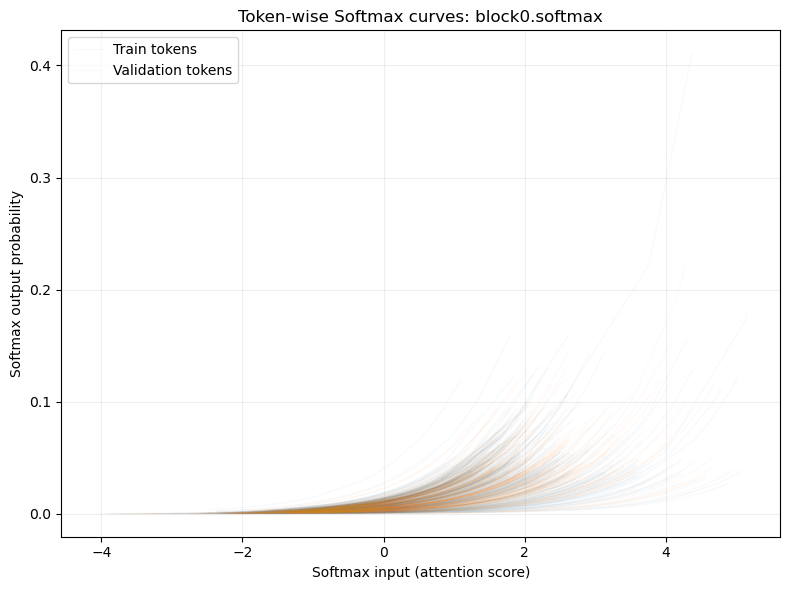

In [15]:
# ============================================================
# Softmax: all selected token curves on ONE figure
# ============================================================

plot_softmax_curves(
    train_curve_collector,
    val_curve_collector,
    module_name=SOFTMAX_MODULE,
    save_path="softmax_curves.png",
)


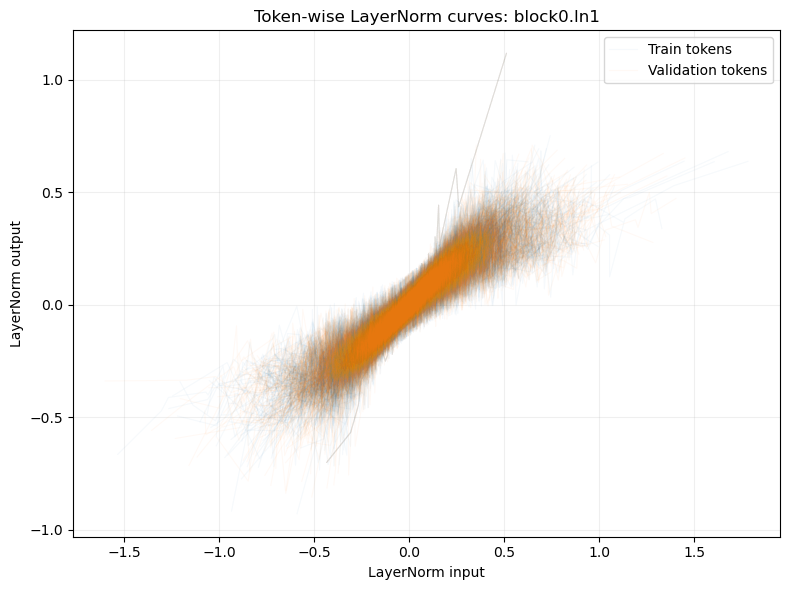

In [16]:
# ============================================================
# LayerNorm: all selected token curves on ONE figure
# ============================================================

plot_layernorm_curves(
    train_curve_collector,
    val_curve_collector,
    module_name=LAYERNORM_MODULE,
    save_path="layernorm_curves.png",
)


## Optional: inspect all three attention blocks quickly

This produces three Softmax figures and six LayerNorm figures only when explicitly executed.


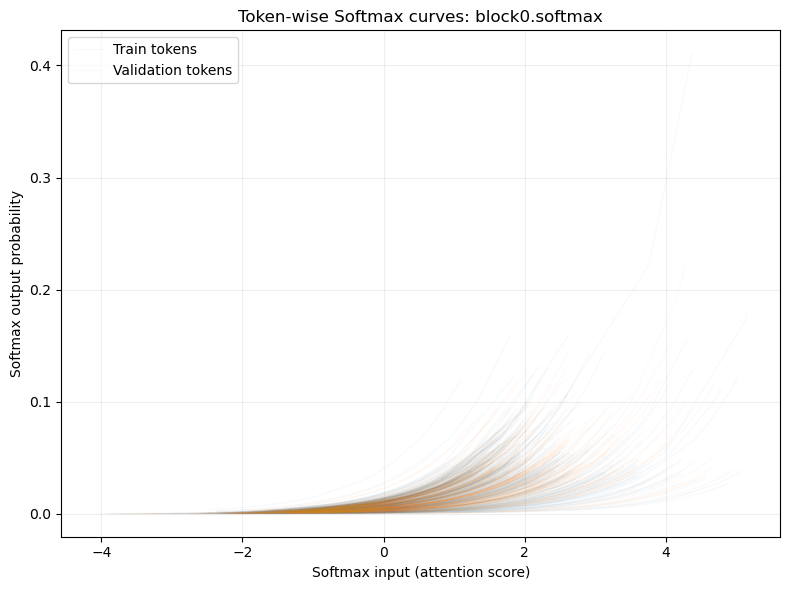

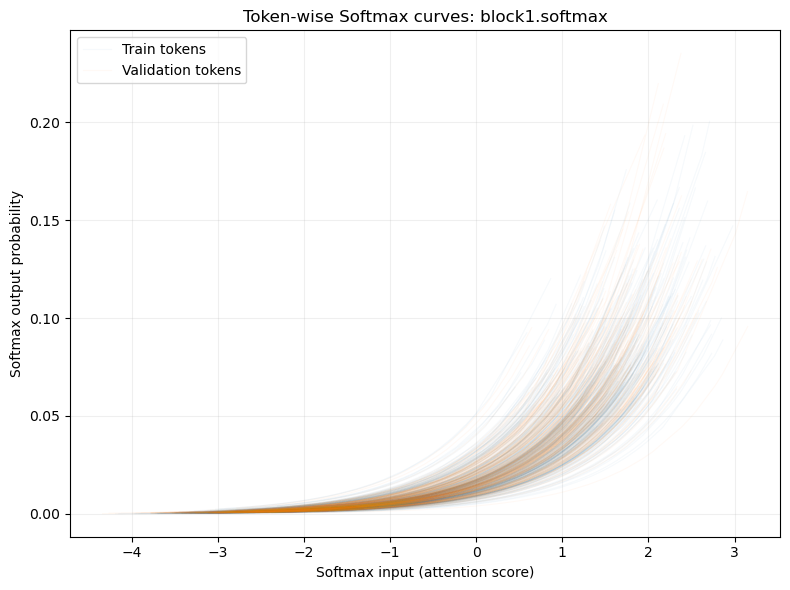

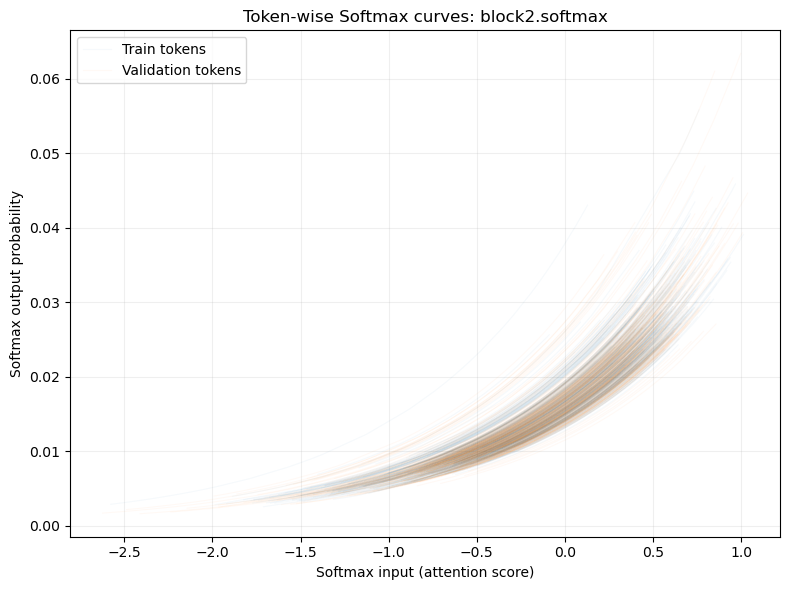

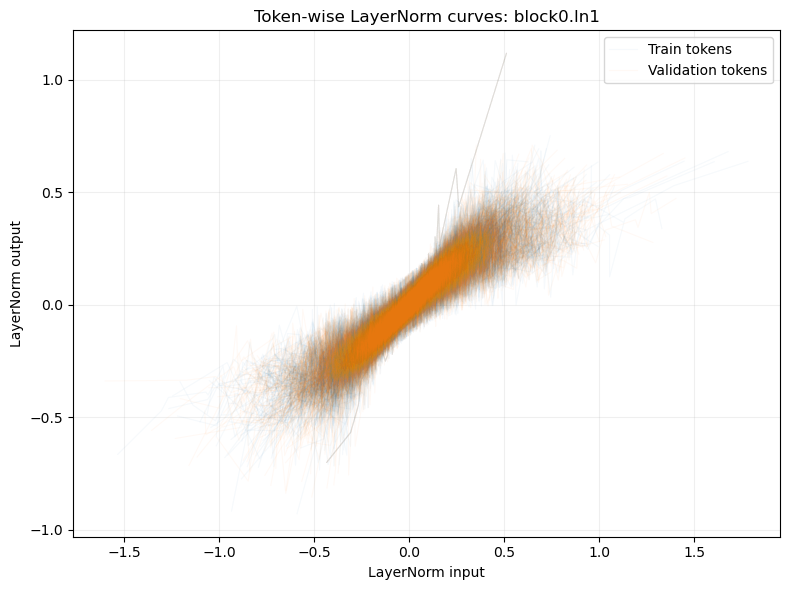

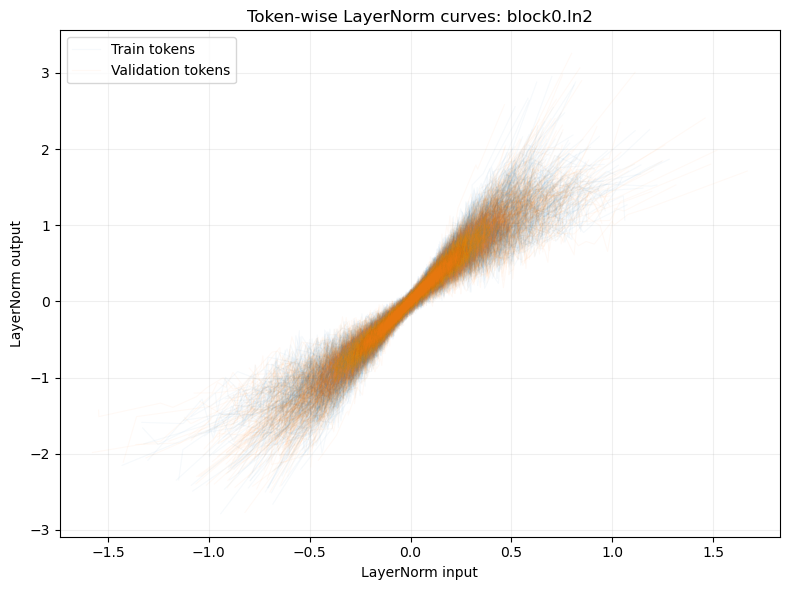

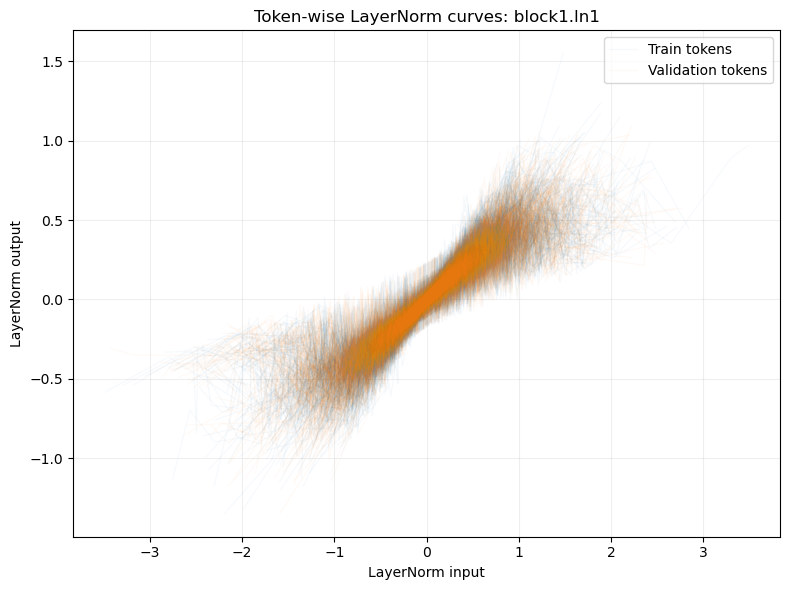

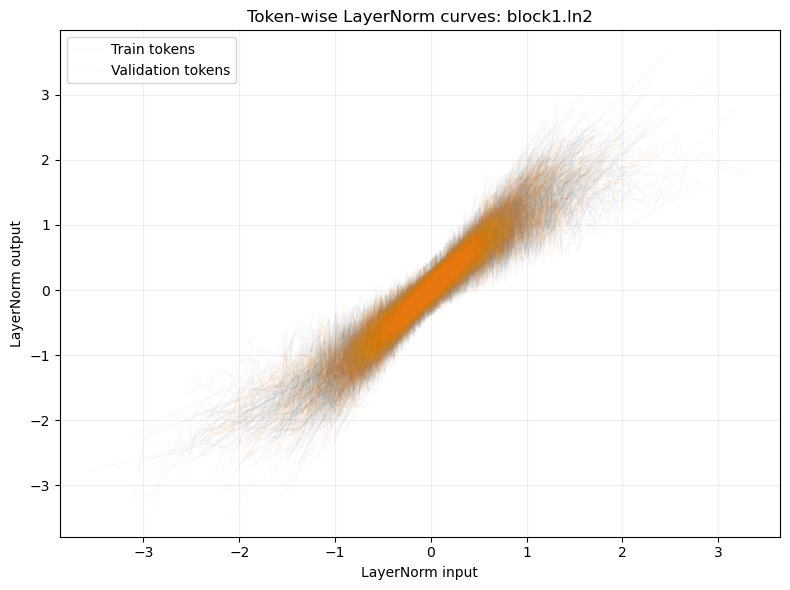

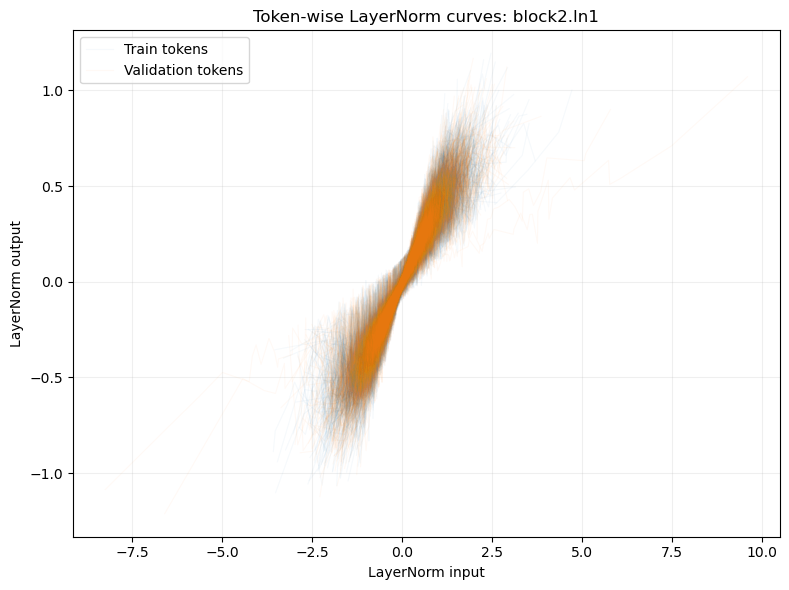

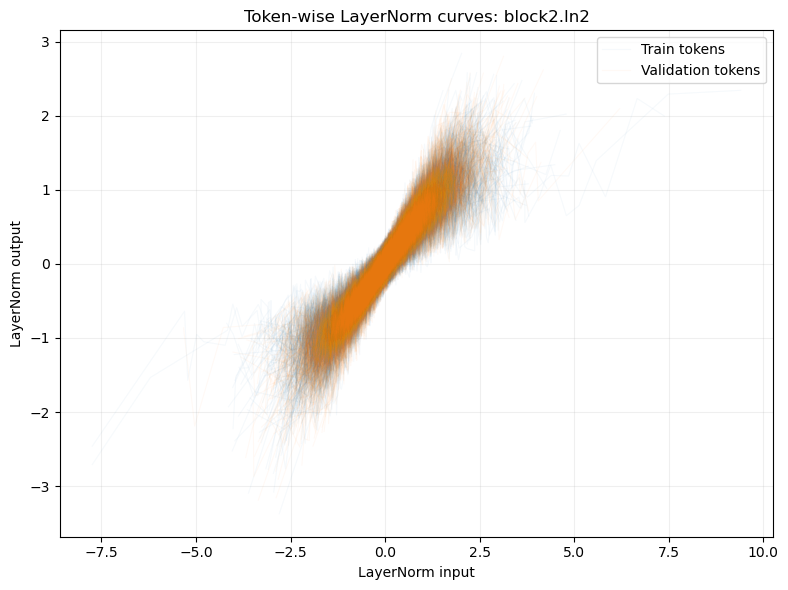

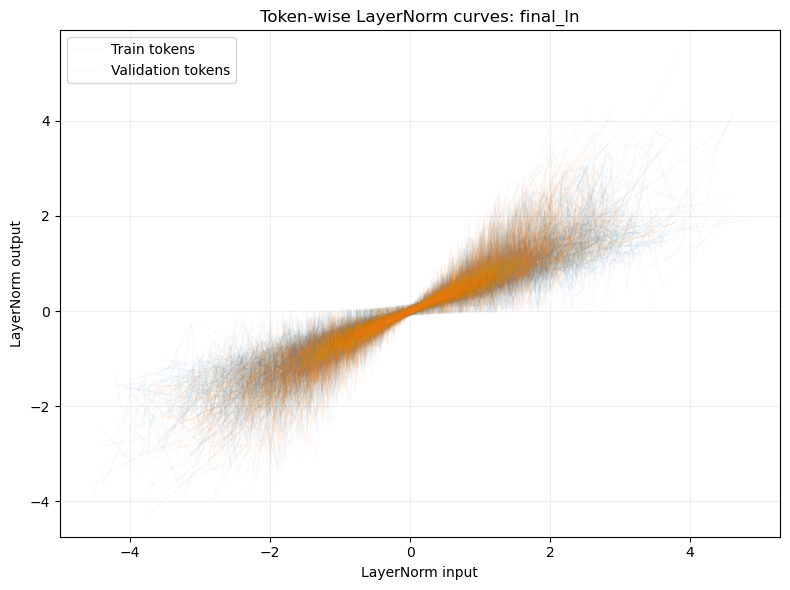

In [17]:
# Optional: uncomment if you want to inspect all blocks.

for module_name in [
    "block0.softmax",
    "block1.softmax",
    "block2.softmax",
]:
    plot_softmax_curves(
        train_curve_collector,
        val_curve_collector,
        module_name=module_name,
    )

for module_name in [
    "block0.ln1",
    "block0.ln2",
    "block1.ln1",
    "block1.ln2",
    "block2.ln1",
    "block2.ln2",
    "final_ln",
]:
    plot_layernorm_curves(
        train_curve_collector,
        val_curve_collector,
        module_name=module_name,
    )
